In [1]:
"""
Figure 4 - Contribution of changing ice geometry to the observed acceleration at LEV6 (2009-2021).
Author: Hannah Picton & Andrew Tedstone
Date: 5th November 2026
Description: This notebook calculates and plots the modelled change in annual ice displacement at LEV6 between 2009 and 2021
resulting from the observed changes in ice surface slope and ice thickness, under (i) a frozen bed (internal deformation only),
and (ii) hard-bed and (iii) soft-bed regularised-Coulomb sliding scenarios across a range of basal sliding fractions.
Calculations follow Equations 1-3 of the associated manuscript and the Supplementary Methods, and reproduce those in
'processing/driving_stress_calculation.ipynb'. A height uncertainty of ±0.25 m is propagated.
"""

# Import libraries 
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D

In [2]:
# ==========================================================================================
# Input data (as used in driving_stress_calculation notebook)
# ==========================================================================================
# LEV5 (pole-corrected ellipsoidal heights, geoid correction and bed elevation from BedMachine v5)
lev5_geoid_correction = 37
lev5_bed = 243.05
lev5_2009_height = 1481.71 - lev5_geoid_correction
lev5_2021_height = 1475.75 - lev5_geoid_correction

# LEV6
lev6_geoid_correction = 39
lev6_bed = 234.31
lev6_2009_height = 1713.49 - lev6_geoid_correction
lev6_2021_height = 1710.73 - lev6_geoid_correction
lev6_2009_thickness = lev6_2009_height - lev6_bed
lev6_2021_thickness = lev6_2021_height - lev6_bed  

# Distance between LEV5 and LEV6 (from PPP outputs)
dist_2009 = 35961.199784999364
dist_2021 = 35985.817838664356

# Velocity parameters
init_vel = 62.6            # annual ice velocity at LEV6 in 2009 (m yr-1)
observed_delta_v = 3.2     # observed increase in annual ice displacement at LEV6, 2009-2021 (m)
n = 3                      # Glen's flow-law exponent
uncertainty_H = 0.25       # height uncertainty (m)

# ==========================================================================================
# Relative changes in slope and thickness, and their uncertainties
# ==========================================================================================
slope_2009 = (lev6_2009_height - lev5_2009_height) / dist_2009
slope_2021 = (lev6_2021_height - lev5_2021_height) / dist_2021
delta_s = slope_2021 - slope_2009
delta_thickness = lev6_2021_thickness - lev6_2009_thickness
X_S = delta_s / slope_2009
X_T = delta_thickness / lev6_2009_thickness

uncertainty_H_diff = math.sqrt(2 * uncertainty_H**2)
delta_slope_2009 = abs(slope_2009) * (uncertainty_H_diff / (lev6_2009_height - lev5_2009_height))
delta_slope_2021 = abs(slope_2021) * (uncertainty_H_diff / (lev6_2021_height - lev5_2021_height))
delta_delta_s = math.sqrt(delta_slope_2009**2 + delta_slope_2021**2)
delta_T = math.sqrt(2 * uncertainty_H**2)
delta_delta_T = math.sqrt(2 * delta_T**2)
delta_X_S = abs(X_S) * math.sqrt((delta_delta_s / abs(delta_s))**2 + (delta_slope_2009 / abs(slope_2009))**2)
delta_X_T = abs(X_T) * math.sqrt((delta_delta_T / abs(delta_thickness))**2 + (uncertainty_H / lev6_2009_thickness)**2)

In [3]:
# ==========================================================================================
# Response equations (Equations 3-5; Supplementary Methods)
# ==========================================================================================
def deformation_response(dS, dH, err_dS, err_dH, U0):
    delU = U0 * ((n + 1) * dH + n * dS)
    err = U0 * math.sqrt(((n + 1) * err_dH)**2 + (n * err_dS)**2)
    return delU, err

def sliding_response(dS, dH, err_dS, err_dH, p, ut, U0):
    delU = U0 * (1 + U0 / ut) * (p * dH + p * dS)
    err = U0 * (1 + U0 / ut) * math.sqrt((p * err_dH)**2 + (p * err_dS)**2)
    return delU, err

def generalised_response(basal_fraction, p, ut):
    Ub = basal_fraction * init_vel
    Ud = init_vel - Ub
    dUb, eUb = sliding_response(X_S, X_T, delta_X_S, delta_X_T, p, ut, Ub)
    dUd, eUd = deformation_response(X_S, X_T, delta_X_S, delta_X_T, Ud)
    return dUb + dUd, math.sqrt(eUb**2 + eUd**2)

# Scenarios
basal_fractions = [0.60, 0.70, 0.80, 0.90, 0.96]
scenarios = {'hard': {'p': 3, 'ut': 300}, 'soft': {'p': 5, 'ut': 100}}
rows = [{'scenario': 'frozen', 'basal_fraction': 0.0, **dict(zip(['delta_m', 'err_m'], generalised_response(0.0, 3, 300)))}]
for name, s in scenarios.items():
    for bf in basal_fractions:
        rows.append({'scenario': name, 'basal_fraction': bf, **dict(zip(['delta_m', 'err_m'], generalised_response(bf, s['p'], s['ut'])))})
results = pd.DataFrame(rows)
results['pct_observed'] = 100 * results['delta_m'] / observed_delta_v
results['pct_observed_err'] = 100 * results['err_m'] / observed_delta_v
print(results.round(1).to_string(index=False))

scenario  basal_fraction  delta_m  err_m  pct_observed  pct_observed_err
  frozen             0.0      2.0    0.4          62.7              13.1
    hard             0.6      2.2    0.3          69.9              10.2
    hard             0.7      2.3    0.4          72.1              11.1
    hard             0.8      2.4    0.4          74.5              12.3
    hard             0.9      2.5    0.4          77.3              13.9
    hard             1.0      2.5    0.5          79.0              14.9
    soft             0.6      3.7    0.6         116.4              18.5
    soft             0.7      4.2    0.7         130.2              22.0
    soft             0.8      4.7    0.8         145.4              26.0
    soft             0.9      5.2    1.0         162.0              30.3
    soft             1.0      5.5    1.1         172.6              33.1


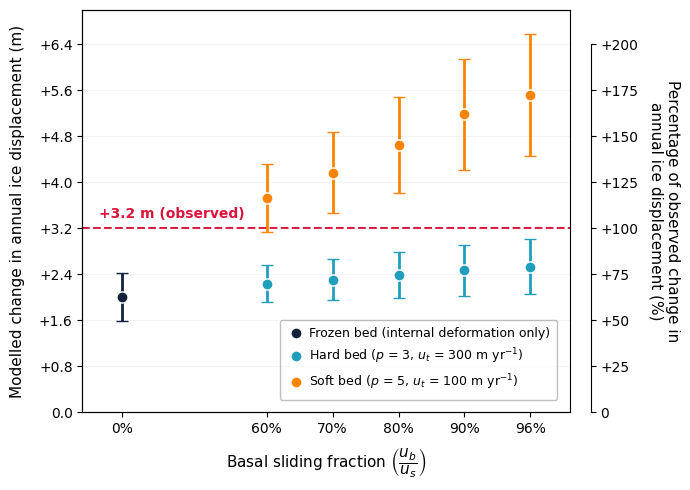

In [4]:
# ==========================================================================================
# Plot modelled change in annual ice displacement at LEV6 (2009-2021) for each scenario
# ==========================================================================================
def plus_minus_formatter_1dp(value, pos):
    return f"+{value:.1f}" if value > 0 else (f"{value:.1f}" if value < 0 else "0.0")

def plus_minus_formatter(value, pos):
    return f"+{value:g}" if value > 0 else (f"{value:g}" if value < 0 else "0")

# Plot colours and parameters
colors = {'frozen': '#14213d', 'hard': '#219ebc', 'soft': '#fb8500'}
labels = {'frozen': 'Frozen bed (internal deformation only)',
          'hard': r'Hard bed ($p$ = 3, $u_t$ = 300 m yr$^{-1}$)',
          'soft': r'Soft bed ($p$ = 5, $u_t$ = 100 m yr$^{-1}$)'}
x_mapping = {0.0: 0, 0.60: 2.2, 0.70: 3.2, 0.80: 4.2, 0.90: 5.2, 0.96: 6.2}   # gap between frozen bed and sliding scenarios
observed_color = 'crimson'

fig, ax1 = plt.subplots(figsize=(7, 5))
for name, grp in results.groupby('scenario', sort=False):
    x = grp['basal_fraction'].map(x_mapping)
    ax1.errorbar(x, grp['delta_m'], yerr=grp['err_m'], fmt='o', color=colors[name], ecolor=colors[name],
                 elinewidth=2, capsize=4, capthick=1.5, markersize=8, markeredgecolor='white', markeredgewidth=1, zorder=5)

# Observed increase (3.2 m)
ax1.axhline(observed_delta_v, color=observed_color, linestyle='--', linewidth=1.5, zorder=1)
ax1.text(-0.35, observed_delta_v + 0.12, f'+{observed_delta_v} m (observed)', color=observed_color, fontsize=10, weight='bold', va='bottom')

# Axes formatting
ax1.set_xticks(list(x_mapping.values()))
ax1.set_xticklabels([f'{int(round(bf * 100))}%' for bf in x_mapping.keys()], fontsize=10)
ax1.set_xlim(-0.6, 6.8)
ax1.set_xlabel(r'Basal sliding fraction $\left(\dfrac{u_b}{u_s}\right)$', fontsize=11, labelpad=8)
ax1.set_ylim(0, 7)
ax1.set_yticks(np.arange(0, 7, 0.25 * observed_delta_v))  # every 0.8 m, so gridlines align with the 25% ticks on the right-hand axis
ax1.set_ylabel('Modelled change in annual ice displacement (m)', fontsize=11, labelpad=10)
ax1.yaxis.set_major_formatter(FuncFormatter(plus_minus_formatter_1dp))
ax1.grid(axis='y', linestyle='-', alpha=0.15, zorder=0)

# Secondary y-axis: percentage of observed change, offset outward
ax2 = ax1.twinx()
ax2.spines['right'].set_position(('outward', 15))
ax2.set_ylim(100 * np.array(ax1.get_ylim()) / observed_delta_v)
ax2.set_yticks(np.arange(0, 201, 25))
ax2.spines['right'].set_bounds(0, 200)
ax2.yaxis.set_major_formatter(FuncFormatter(plus_minus_formatter))
ax2.set_ylabel('Percentage of observed change in\nannual ice displacement (%)', fontsize=11, labelpad=30, rotation=270)

# Legend
handles = [Line2D([0], [0], marker='o', color=colors[k], linestyle='none', markersize=8,
                  markeredgecolor='white', markeredgewidth=1, label=labels[k]) for k in ['frozen', 'hard', 'soft']]
ax1.legend(handles=handles, loc='lower right', fontsize=9, borderpad=0.6, borderaxespad=1,
           handletextpad=0.4, handlelength=1.3, facecolor='white', framealpha=0.5, edgecolor='grey')

plt.tight_layout()
plt.show()